# Using GEOparse Python Package - Microglia Data in GEO

In [1]:
!pip install GEOparse odfpy anndata scanpy pooch igraph mygene

  Using cached GEOparse-2.0.4-py3-none-any.whl.metadata (6.5 kB)
  Using cached odfpy-1.4.1-py2.py3-none-any.whl
  Using cached anndata-0.12.10-py3-none-any.whl.metadata (9.9 kB)
  Using cached scanpy-1.12-py3-none-any.whl.metadata (8.4 kB)
  Using cached pooch-1.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached igraph-1.0.0-cp39-abi3-manylinux_2_28_x86_64.whl.metadata (4.4 kB)
  Using cached mygene-3.2.2-py2.py3-none-any.whl.metadata (10 kB)
  Using cached array_api_compat-1.14.0-py3-none-any.whl.metadata (2.5 kB)
  Using cached legacy_api_wrap-1.5-py3-none-any.whl.metadata (2.2 kB)
  Using cached natsort-8.4.0-py3-none-any.whl.metadata (21 kB)
  Using cached zarr-3.1.5-py3-none-any.whl.metadata (10 kB)
  Using cached fast_array_utils-1.3.1-py3-none-any.whl.metadata (3.9 kB)
  Using cached packaging-26.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached pynndescent-0.6.0-py3-none-any.whl.metadata (6.9 kB)
  Using cached session_info2-0.4-py3-none-any.whl.metadata (3.5 kB)
  Using c

In [2]:
from __future__ import annotations
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
import GEOparse
import requests
import gzip
import io
import anndata as ad
import pooch
import scanpy as sc
import mygene

## Create dictionary of compiled GSEs from research

In [3]:
gse_dict = {
            "Transcriptomic profiling of microglia and astrocytes throughout aging": 137028,
            "Time-dependent changes in microglia transcriptional networks following traumatic brain injury": 132809,
            "Temporal tracking of microglia activation in neurodegeneration at single-cell resolution": 103334,
            "Transcriptional profiling of microglia; current state of the art and future perspectives": 135618,
            "Microglial reactivity and neuroinflammation-driven in motivational behaviors are regulated by Orai1 channels": 310141
           }

## GSE 132809 

### Experimental Design Clarification for above CCI Microglia NanoString Dataset
**Study Structure based on the Methods and Results sections**:
- Model: Controlled cortical impact (CCI)
- Subjects: 2-month-old male C57BL/6J mice

**Groups**:
- Sham (n = 4), 2 dpi (n = 4), 14 dpi (n = 4), 60 dpi (n = 3)

**Microglia were**:
- Isolated from brain tissue via enzymatic digestion
- Stained for CD11b and CD45
- Sorted using FACS
- RNA extracted and analyzed using NanoString nCounter (550 inflammation/immunity genes)

In [4]:
gse_132809 = GEOparse.get_GEO(geo="GSE132809", destdir="./")

21-Mar-2026 21:03:18 DEBUG utils - Directory ./ already exists. Skipping.
21-Mar-2026 21:03:18 INFO GEOparse - File already exist: using local version.
21-Mar-2026 21:03:18 INFO GEOparse - Parsing ./GSE132809_family.soft.gz: 
21-Mar-2026 21:03:18 DEBUG GEOparse - DATABASE: GeoMiame
21-Mar-2026 21:03:18 DEBUG GEOparse - SERIES: GSE132809
21-Mar-2026 21:03:18 DEBUG GEOparse - PLATFORM: GPL26788
21-Mar-2026 21:03:18 DEBUG GEOparse - SAMPLE: GSM3892735
21-Mar-2026 21:03:18 DEBUG GEOparse - SAMPLE: GSM3892736
21-Mar-2026 21:03:18 DEBUG GEOparse - SAMPLE: GSM3892737
21-Mar-2026 21:03:18 DEBUG GEOparse - SAMPLE: GSM3892738
21-Mar-2026 21:03:18 DEBUG GEOparse - SAMPLE: GSM3892739
21-Mar-2026 21:03:18 DEBUG GEOparse - SAMPLE: GSM3892740
21-Mar-2026 21:03:18 DEBUG GEOparse - SAMPLE: GSM3892741
21-Mar-2026 21:03:18 DEBUG GEOparse - SAMPLE: GSM3892742
21-Mar-2026 21:03:18 DEBUG GEOparse - SAMPLE: GSM3892743
21-Mar-2026 21:03:18 DEBUG GEOparse - SAMPLE: GSM3892744
21-Mar-2026 21:03:18 DEBUG GEOpars

In [5]:
for i, (gpl_name, gpl) in enumerate(gse_132809.gpls.items()):
    print("Name: ", gpl_name)
    print("Metadata:",)
    for key, value in gpl.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print("Table data:",)
    print(gpl.table.head())

Name:  GPL26788
Metadata:
 - title : NanoString nCounter® Mouse Inflammation v2 Panel
 - geo_accession : GPL26788
 - status : Public on Jun 18 2019
 - submission_date : Jun 17 2019
 - last_update_date : Jun 18 2019
 - technology : other
 - distribution : custom-commercial
 - organism : Mus musculus
 - taxid : 10090
 - manufacturer : Nanostring
 - manufacture_protocol : see manufacturer's website
 - contact_name : Michael,,Whalen
 - contact_email : mwhalen@mgh.harvard.edu
 - contact_phone : 617-643-3933
 - contact_laboratory : Acute Brain Injury Research Laboratory
 - contact_department : Department of Pediatrics
 - contact_institute : Massachusetts General Hospital
 - contact_address : 149 13th Street Room 6303
 - contact_city : Charlestown
 - contact_state : MA
 - contact_zip/postal_code : 02129
 - contact_country : USA
 - data_row_count : 547
Table data:
            ID  Code.Class Gene.Name       GB_ACC
0  NM_019552.2  Endogenous    Abcb10  NM_019552.2
1  NM_011076.1  Endogenous    A

In [6]:
for i, (gsm_name, gsm) in enumerate(gse_132809.gsms.items()):
    print("Name: ", gsm_name)
    print("Metadata:",)
    for key, value in gsm.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print ("Table data:",)
    print (gsm.table.head(20))
    if i==0:
        break
    

Name:  GSM3892735
Metadata:
 - title : 20141015_cci_01_01.RCC
 - geo_accession : GSM3892735
 - status : Public on Jun 18 2019
 - submission_date : Jun 17 2019
 - last_update_date : Jun 18 2019
 - type : RNA
 - channel_count : 1
 - source_name_ch1 : brain
 - organism_ch1 : Mus musculus
 - taxid_ch1 : 10090
 - characteristics_ch1 : injury: sham
 - treatment_protocol_ch1 : NA
 - growth_protocol_ch1 : NA
 - molecule_ch1 : total RNA
 - extract_protocol_ch1 : Microglia isolated by FACS were stored in RNAlater Stabilization Solution (AM7020, Invitrogen) at -80°C until further processing. Total RNA from the sorted cells was extracted using miRNeasy Micro Kit from Qiagen (Redwood City, CA) for purification of total RNA from small amounts of cells according to the manufacturer's instructions. mRNA expression analysis with the NanoString nCounter® Mouse Inflammation v2 Panel was performed according to the manufacturer's protocol (NanoString Technologies Inc., Seattle, WA).
 - label_ch1 : N/A
 - l

## GSE 137028 

### Data Structure Clarification
This dataset is RNA-seq (“Expression profiling by high throughput sequencing”). Although GEO lists 60 samples, GEOparse does not return per-GSM SOFT expression tables because the processed data were not stored in individual GSM records.

**Instead**:
- Raw sequencing data are stored in SRA (BioProject PRJNA564299; SRP220678).
- The processed expression matrix is provided as a single supplementary file: `GSE137028_gene_fpkm.xls.gz`

**This file contains**:
- 35,999 genes
- 20 biological samples (columns)
- FPKM-normalized expression values

The 60 samples listed in GEO likely correspond to raw sequencing runs or technical libraries, which were aggregated into 20 condition-level profiles in the processed matrix.

**Factorial Column names**:
- Genotype: WT vs AD
- Age: 2m, 4m, 6m, 9m, 12m
- Group (likely sex): M and A

So there are **2×5×2=20 processed samples**

Thus, GEOparse shows no GSM tables because the usable expression data are stored in the supplementary file rather than in SOFT-formatted per-sample tables.

In [7]:
gse_137028 = GEOparse.get_GEO(geo="GSE137028", destdir="./")

21-Mar-2026 21:03:21 DEBUG utils - Directory ./ already exists. Skipping.
21-Mar-2026 21:03:21 INFO GEOparse - File already exist: using local version.
21-Mar-2026 21:03:21 INFO GEOparse - Parsing ./GSE137028_family.soft.gz: 
21-Mar-2026 21:03:21 DEBUG GEOparse - DATABASE: GeoMiame
21-Mar-2026 21:03:21 DEBUG GEOparse - SERIES: GSE137028
21-Mar-2026 21:03:21 DEBUG GEOparse - PLATFORM: GPL24247
21-Mar-2026 21:03:21 DEBUG GEOparse - SAMPLE: GSM4065891
21-Mar-2026 21:03:21 DEBUG GEOparse - SAMPLE: GSM4065892
21-Mar-2026 21:03:21 DEBUG GEOparse - SAMPLE: GSM4065893
21-Mar-2026 21:03:21 DEBUG GEOparse - SAMPLE: GSM4065894
21-Mar-2026 21:03:21 DEBUG GEOparse - SAMPLE: GSM4065895
21-Mar-2026 21:03:21 DEBUG GEOparse - SAMPLE: GSM4065896
21-Mar-2026 21:03:21 DEBUG GEOparse - SAMPLE: GSM4065897
21-Mar-2026 21:03:21 DEBUG GEOparse - SAMPLE: GSM4065898
21-Mar-2026 21:03:21 DEBUG GEOparse - SAMPLE: GSM4065899
21-Mar-2026 21:03:21 DEBUG GEOparse - SAMPLE: GSM4065900
21-Mar-2026 21:03:21 DEBUG GEOpars

In [8]:
for i, (gpl_name, gpl) in enumerate(gse_137028.gpls.items()):
    print("Name: ", gpl_name)
    print("Metadata:",)
    for key, value in gpl.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print("Table data:",)
    print(gpl.table.head())

Name:  GPL24247
Metadata:
 - title : Illumina NovaSeq 6000 (Mus musculus)
 - geo_accession : GPL24247
 - status : Public on Nov 08 2017
 - submission_date : Nov 08 2017
 - last_update_date : Mar 08 2019
 - technology : high-throughput sequencing
 - distribution : virtual
 - organism : Mus musculus
 - taxid : 10090
 - contact_name : ,,GEO
 - contact_country : USA
 - data_row_count : 0
Table data:
Empty DataFrame
Columns: []
Index: []


In [9]:
for i, (gsm_name, gsm) in enumerate(gse_137028.gsms.items()):
    print("Name: ", gsm_name)
    print("Metadata:",)
    for key, value in gsm.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print ("Table data:",)
    print (gsm.table.head(20))
    if i==0:
        break
    

Name:  GSM4065891
Metadata:
 - title : WT2m1M
 - geo_accession : GSM4065891
 - status : Public on Apr 17 2020
 - submission_date : Sep 06 2019
 - last_update_date : Apr 17 2020
 - type : SRA
 - channel_count : 1
 - source_name_ch1 : Brain
 - organism_ch1 : Mus musculus
 - taxid_ch1 : 10090
 - characteristics_ch1 : strain: C57BL/6, age: 2-month-old
 - molecule_ch1 : total RNA
 - extract_protocol_ch1 : RNA was isolated from flow cytometry-sorted cell populations using RNeasy Micro Kit (74004, Qiagen), A total amount of 10 ng RNA per sample was used as input material for the RNA sample preparations. Libraries were generated using SMART-Seq v4 Ultra Low Input RNA Kit (634892, Takara Bio USA, Mountain View, CA, USA) following manufacturer’s recommendations and index codes were added to attribute sequences to each sample. Briefly, first-strand cDNA synthesis from total RNA is primed by the 3’ SMART-Seq CDS Primer II A and uses the SMART-Seq v4 Oligonucleotide for template switching at the 5’

In [10]:
print(gse_137028.metadata.get("type", []))
print(gse_137028.metadata.get("supplementary_file", [])[:10])
print(gse_137028.relations)

['Expression profiling by high throughput sequencing']
['ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE137nnn/GSE137028/suppl/GSE137028_gene_fpkm.xls.gz']
{'BioProject': ['https://www.ncbi.nlm.nih.gov/bioproject/PRJNA564299'], 'SRA': ['https://www.ncbi.nlm.nih.gov/sra?term=SRP220678']}


In [11]:
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE137nnn/GSE137028/suppl/GSE137028_gene_fpkm.xls.gz"
r = requests.get(url)
compressed_file = io.BytesIO(r.content)
with gzip.open(compressed_file) as f:
    df_137028 = pd.read_excel(f)

print(df_137028.head())
print(df_137028.shape)

              gene_id         WT2mM         WT4mM         WT6mM         WT9mM  \
0  ENSMUSG00000027447  68165.002270  77992.193419  66575.831713  43885.059333   
1  ENSMUSG00000024661   3845.103176   3692.195390   4967.818359   4061.208478   
2  ENSMUSG00000038642  12817.844190  13731.290151  19752.756756  11134.137593   
3  ENSMUSG00000049775  10578.664606  10245.166862  12059.352638   8408.865137   
4  ENSMUSG00000036905  10487.262630  11009.635127  13231.701913   7128.882128   

         WT12mM         AD2mM         AD4mM         AD6mM         AD9mM  ...  \
0  39332.275233  76493.920895  51811.192955  64800.386824  38448.689027  ...   
1   3834.502813   4023.522699   3927.298858   4896.643218   3907.164574  ...   
2   9986.886380  13577.022817  11830.694712  18414.985153   8232.700179  ...   
3   6129.744878  10192.700050   9137.571661  13293.544775   6169.016818  ...   
4   7616.056069  12719.295809  10962.208895  13423.054268   5844.781359  ...   

          WT2mA         WT4mA   

## MOVE AWAY FROM AGGREGATE VALUES FROM SAMPLES, NEED SINGLE CELL GENETIC EXPRESSION

## GSE 103334 (Single cell)

### Data Clarification
This dataset contains single cell RNA-seq (“Expression profiling by high throughput sequencing”). Across 6 weeks (4 time points) we measure about 576 cells (except week 6), totaling 2208 observations. They measure 23951 gene expression values for all.

- **Summary**: Briefly, by using a severe neurodegeneration mouse model with Alzheimer’s-like pathology and phenotypes (CK-p25 model), we surveyed microglia activation by RNA sequencing longitudinally at fine temporal- and single-cell resolution. In summary, our work identified previously unobserved heterogeneity in the response of microglia to neurodegeneration, discovered novel microglia cell states, revealed the trajectory of cellular reprogramming of microglia in response to neurodegeneration, and uncovered the underlying transcriptional programs.

- **Design**: Used the CK-p25 mouse model of severe neurodegeneration which develops AD-like pathology in an inducible and temporally predictable manner. We isolated cells expressing the microglia markers CD11b and CD45 from the hippocampus of three to four CK-p25 animals and three CK control littermates at each of the following four time points during the progression of neurodegeneration: before p25 induction (0 weeks), 1 week, 2 weeks, and 6 weeks after p25 induction. Single microglial cells (expressing the cell surface markers CD11b and CD45) were sorted directly into RNA lysis buffer in 96-well plates using Fluorescence-Activated Cell Sorting (FACS). We prepared a total of 2183 single-cell RNA-sequencing libraries using a modified version of the Smart-Seq2 protocol and sequenced the libraries to a depth of 251353 (median) mapped reads per cell.

In [12]:
gse_103334 = GEOparse.get_GEO(geo="GSE103334", destdir="./")

21-Mar-2026 21:03:36 DEBUG utils - Directory ./ already exists. Skipping.
21-Mar-2026 21:03:36 INFO GEOparse - File already exist: using local version.
21-Mar-2026 21:03:36 INFO GEOparse - Parsing ./GSE103334_family.soft.gz: 
21-Mar-2026 21:03:36 DEBUG GEOparse - DATABASE: GeoMiame
21-Mar-2026 21:03:36 DEBUG GEOparse - SERIES: GSE103334
21-Mar-2026 21:03:36 DEBUG GEOparse - PLATFORM: GPL13112
21-Mar-2026 21:03:36 DEBUG GEOparse - SAMPLE: GSM2766573
21-Mar-2026 21:03:36 DEBUG GEOparse - SAMPLE: GSM2766574
21-Mar-2026 21:03:36 DEBUG GEOparse - SAMPLE: GSM2766575
21-Mar-2026 21:03:36 DEBUG GEOparse - SAMPLE: GSM2766576
21-Mar-2026 21:03:37 DEBUG GEOparse - SAMPLE: GSM2766577
21-Mar-2026 21:03:37 DEBUG GEOparse - SAMPLE: GSM2766578
21-Mar-2026 21:03:37 DEBUG GEOparse - SAMPLE: GSM2766579
21-Mar-2026 21:03:37 DEBUG GEOparse - SAMPLE: GSM2766580
21-Mar-2026 21:03:37 DEBUG GEOparse - SAMPLE: GSM2766581
21-Mar-2026 21:03:37 DEBUG GEOparse - SAMPLE: GSM2766582
21-Mar-2026 21:03:37 DEBUG GEOpars

In [13]:
for i, (gpl_name, gpl) in enumerate(gse_103334.gpls.items()):
    print("Name: ", gpl_name)
    print("Metadata:",)
    for key, value in gpl.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print("Table data:",)
    print(gpl.table.head())

Name:  GPL13112
Metadata:
 - title : Illumina HiSeq 2000 (Mus musculus)
 - geo_accession : GPL13112
 - status : Public on Feb 02 2011
 - submission_date : Feb 02 2011
 - last_update_date : Mar 19 2019
 - technology : high-throughput sequencing
 - distribution : virtual
 - organism : Mus musculus
 - taxid : 10090
 - contact_name : ,,GEO
 - contact_country : USA
 - data_row_count : 0
Table data:
Empty DataFrame
Columns: []
Index: []


### GEO is not storing a probe/gene annotation table in the GPL the way it often does for microarrays, this happens because RNA-seq GEO datasets, especially those deposited as processed expression matrices or SRA-linked sequencing studies, GEO often does not provide a full per-feature annotation table in the platform object.

In [14]:
for i, (gsm_name, gsm) in enumerate(gse_103334.gsms.items()):
    print("Name: ", gsm_name)
    print("Metadata:",)
    for key, value in gsm.metadata.items():
        print(" - %s : %s" % (key, ", ".join(value)))
    print ("Table data:",)
    print (gsm.table.head(20))
    if i==0:
        break


Name:  GSM2766573
Metadata:
 - title : RNA-Seq single cell_CK_2w_m2_A1
 - geo_accession : GSM2766573
 - status : Public on Oct 10 2017
 - submission_date : Aug 31 2017
 - last_update_date : May 15 2019
 - type : SRA
 - channel_count : 1
 - source_name_ch1 : CK_2w_m2
 - organism_ch1 : Mus musculus
 - taxid_ch1 : 10090
 - characteristics_ch1 : strain: CK, age: 3 months and 2 weeks, cell type: isolated, FACS sorted single hippocampal microglia
 - molecule_ch1 : total RNA
 - extract_protocol_ch1 : Hippocampal tissue was enzymatically digested using the Neural Tissue Dissociation Kit (P) (Miltenyi Biotec, catalogue number 130-092-628) according to the manufacturer’s protocol., FACS sorted single cell lysis in 96-well plates were subject to Smart-seq2 RNA library preparation. A QC step was performed to check amplification of the libraries before multiplexing for sequencing., RNA from single cells was first purified with Agencourt RNAClean XP beads (Beckman Coulter, catalogue number A63987) b

In [15]:
print(gse_103334.metadata.get("type", []))
print(gse_103334.metadata.get("supplementary_file", [])[:10])
print(gse_103334.relations)

['Expression profiling by high throughput sequencing']
['ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE103nnn/GSE103334/suppl/GSE103334_FPKM_CKP25_TOPHAT.txt.gz']
{'BioProject': ['https://www.ncbi.nlm.nih.gov/bioproject/PRJNA401847']}


## Supplementary file was used for obtaining sample data

### We can model data gaps, interpolating via polynomial fitting for some additional synthetic data?

In [16]:
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE103nnn/GSE103334/suppl/GSE103334_FPKM_CKP25_TOPHAT.txt.gz"
r = requests.get(url)
compressed_file = io.BytesIO(r.content)
with gzip.open(compressed_file) as f:
    df_103334 = pd.read_csv(f, sep='\t')

print(df_103334.head())
print(df_103334.shape)

           GENES  CK_0w_m3_A1  CK_0w_m3_A10  CK_0w_m3_A11  CK_0w_m3_A12  \
0  0610005C13Rik     0.379103           0.0           0.0           0.0   
1  0610007P14Rik    11.727700           0.0           0.0           0.0   
2  0610009B22Rik    22.040700           0.0           0.0           0.0   
3  0610009L18Rik     4.056480           0.0           0.0           0.0   
4  0610009O20Rik    10.932400           0.0           0.0           0.0   

   CK_0w_m3_A2  CK_0w_m3_A3  CK_0w_m3_A4  CK_0w_m3_A5  CK_0w_m3_A6  ...  \
0          0.0          0.0          0.0          0.0          0.0  ...   
1          0.0          0.0          0.0          0.0          0.0  ...   
2          0.0          0.0          0.0          0.0          0.0  ...   
3          0.0          0.0          0.0          0.0          0.0  ...   
4          0.0          0.0          0.0          0.0          0.0  ...   

   CKp25_6w_m4_H11  CKp25_6w_m4_H12  CKp25_6w_m4_H2  CKp25_6w_m4_H3  \
0            0.000         

In [17]:
df_103334.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23951 entries, 0 to 23950
Columns: 2209 entries, GENES to CKp25_6w_m4_H9_0
dtypes: float64(2208), object(1)
memory usage: 403.7+ MB


In [18]:
df_103334.describe()

,CK_0w_m3_A1,CK_0w_m3_A10,CK_0w_m3_A11,CK_0w_m3_A12,CK_0w_m3_A2,CK_0w_m3_A3,CK_0w_m3_A4,CK_0w_m3_A5,CK_0w_m3_A6,CK_0w_m3_A7,...,CKp25_6w_m4_H11,CKp25_6w_m4_H12,CKp25_6w_m4_H2,CKp25_6w_m4_H3,CKp25_6w_m4_H4,CKp25_6w_m4_H5,CKp25_6w_m4_H6,CKp25_6w_m4_H7,CKp25_6w_m4_H8,CKp25_6w_m4_H9_0
count,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,...,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000,23951.000000
mean,15.872177,10.694415,17.333124,13.019686,18.213701,16.179573,17.770292,15.831723,12.108316,11.685200,...,20.090375,17.665154,16.744925,15.936848,18.467950,17.928028,13.351653,20.958837,18.672051,15.751943
std,395.454306,317.799722,397.824780,329.984935,361.918014,397.424481,477.475324,477.160555,267.703832,284.111374,...,454.096437,328.632632,490.759637,270.065156,453.281957,481.313742,318.298733,510.274608,456.118352,245.269284
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.180094,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,5.649805,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,56945.000000,37194.800000,46548.800000,29299.800000,31780.300000,41157.900000,60070.800000,58436.800000,25972.200000,32045.900000,...,54842.900000,22012.300000,60544.300000,26078.600000,60021.100000,61205.700000,35137.100000,58634.000000,61677.700000,27145.900000


In [19]:
df_103334.isna().sum().sum()

np.int64(0)

In [20]:
df_103334.columns

Index(['GENES', 'CK_0w_m3_A1', 'CK_0w_m3_A10', 'CK_0w_m3_A11', 'CK_0w_m3_A12',
       'CK_0w_m3_A2', 'CK_0w_m3_A3', 'CK_0w_m3_A4', 'CK_0w_m3_A5',
       'CK_0w_m3_A6',
       ...
       'CKp25_6w_m4_H11', 'CKp25_6w_m4_H12', 'CKp25_6w_m4_H2',
       'CKp25_6w_m4_H3', 'CKp25_6w_m4_H4', 'CKp25_6w_m4_H5', 'CKp25_6w_m4_H6',
       'CKp25_6w_m4_H7', 'CKp25_6w_m4_H8', 'CKp25_6w_m4_H9_0'],
      dtype='object', length=2209)

### Need to separate the dataframe by observation week, & transpose each so that n*p matrix is result and each included gene list as the column header

In [21]:
gene_list = df_103334.GENES.to_list()

In [22]:
df_103334_0w = df_103334.filter(regex=r'_0w_').T
df_103334_0w.columns = gene_list

In [23]:
df_103334_0w.shape

(576, 23951)

In [24]:
df_103334_1w = df_103334.filter(regex=r'_1w_').T
df_103334_1w.columns = gene_list

In [25]:
df_103334_1w.shape

(576, 23951)

In [26]:
df_103334_2w = df_103334.filter(regex=r'_2w_').T
df_103334_2w.columns = gene_list

In [27]:
df_103334_2w.shape

(576, 23951)

In [28]:
df_103334_6w = df_103334.filter(regex=r'_6w_').T
df_103334_6w.columns = gene_list

In [29]:
df_103334_6w.shape

(480, 23951)

## Take look at 0th week observations

In [30]:
df_103334_0w.head()

,0610005C13Rik,0610007P14Rik,0610009B22Rik,0610009L18Rik,0610009O20Rik,0610010B08Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610012G03Rik,...,Zwilch,Zwint,Zxda,Zxdb,Zxdc,Zyg11a,Zyg11b,Zyx,Zzef1,Zzz3
CK_0w_m3_A1,0.379103,11.7277,22.0407,4.05648,10.9324,0.082063,5.23899,55.5093,8.48037,11.0711,...,0.0,1.71918,1.10084,1.44597,1.99025,0.0,4.16773,7.22038,4.6969,2.42857
CK_0w_m3_A10,0.000000,0.0000,0.0000,0.00000,0.0000,0.000000,0.00000,0.0000,0.00000,0.0000,...,0.0,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.0000,0.00000
CK_0w_m3_A11,0.000000,0.0000,0.0000,0.00000,0.0000,0.000000,0.00000,73.3392,0.00000,0.0000,...,0.0,0.00000,4.44716,0.00000,0.00000,0.0,0.00000,0.00000,0.0000,12.34380
CK_0w_m3_A12,0.000000,0.0000,0.0000,0.00000,0.0000,0.000000,42.88510,0.0000,0.00000,0.0000,...,0.0,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.0000,0.00000
CK_0w_m3_A2,0.000000,0.0000,0.0000,0.00000,0.0000,0.000000,0.00000,0.0000,0.00000,0.0000,...,0.0,0.00000,0.00000,0.00000,0.00000,0.0,0.00000,0.00000,0.0000,0.00000


### Configure ScanPy figure parameters, convert df into Annotated Data object with AnnData and annotate object to include metadata found in GSM and GPL details

In [31]:
sc.set_figure_params(dpi=100, facecolor="white")

In [32]:
adata_103334_0w = ad.AnnData(df_103334_0w)

In [33]:
adata_103334_0w

AnnData object with n_obs × n_vars = 576 × 23951

In [34]:
adata_103334_0w.X

array([[3.79103e-01, 1.17277e+01, 2.20407e+01, ..., 7.22038e+00,
        4.69690e+00, 2.42857e+00],
       [0.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        0.00000e+00, 0.00000e+00],
       [0.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        0.00000e+00, 1.23438e+01],
       ...,
       [0.00000e+00, 0.00000e+00, 1.51743e+02, ..., 0.00000e+00,
        0.00000e+00, 0.00000e+00],
       [0.00000e+00, 0.00000e+00, 5.75027e+02, ..., 0.00000e+00,
        0.00000e+00, 0.00000e+00],
       [0.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        0.00000e+00, 0.00000e+00]])

In [35]:
adata_103334_0w.layers["log_transformed"] = np.log1p(adata_103334_0w.X)

In [36]:
adata_103334_0w.obs_names

Index(['CK_0w_m3_A1', 'CK_0w_m3_A10', 'CK_0w_m3_A11', 'CK_0w_m3_A12',
       'CK_0w_m3_A2', 'CK_0w_m3_A3', 'CK_0w_m3_A4', 'CK_0w_m3_A5',
       'CK_0w_m3_A6', 'CK_0w_m3_A7',
       ...
       'CKp25_0w_m2_H11', 'CKp25_0w_m2_H12', 'CKp25_0w_m2_H2',
       'CKp25_0w_m2_H3', 'CKp25_0w_m2_H4', 'CKp25_0w_m2_H5', 'CKp25_0w_m2_H6',
       'CKp25_0w_m2_H7', 'CKp25_0w_m2_H8', 'CKp25_0w_m2_H9'],
      dtype='object', length=576)

In [37]:
adata_103334_0w.var_names

Index(['0610005C13Rik', '0610007P14Rik', '0610009B22Rik', '0610009L18Rik',
       '0610009O20Rik', '0610010B08Rik', '0610010F05Rik', '0610010K14Rik',
       '0610011F06Rik', '0610012G03Rik',
       ...
       'Zwilch', 'Zwint', 'Zxda', 'Zxdb', 'Zxdc', 'Zyg11a', 'Zyg11b', 'Zyx',
       'Zzef1', 'Zzz3'],
      dtype='object', length=23951)

In [38]:
records = []

for gsm_name, gsm in gse_103334.gsms.items():
    row = {"gsm_id": gsm_name}

    for key, value in gsm.metadata.items():
        row[key] = " | ".join(value) if isinstance(value, list) else value

    title = row.get("title", "")
    if title.startswith("RNA-Seq single cell_"):
        row["sample_alias"] = title.replace("RNA-Seq single cell_", "", 1)
    else:
        row["sample_alias"] = title

    records.append(row)

meta_df = pd.DataFrame(records)

# keep only samples that are in the AnnData object
meta_df = meta_df[meta_df["sample_alias"].isin(adata_103334_0w.obs_names)]

# use sample alias to align with obs_names
meta_df = meta_df.set_index("sample_alias")
meta_df = meta_df.reindex(adata_103334_0w.obs_names)
adata_103334_0w.obs = adata_103334_0w.obs.join(meta_df)

In [39]:
adata_103334_0w.obs.head()

,gsm_id,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,...,contact_zip/postal_code,contact_country,instrument_model,library_selection,library_source,library_strategy,relation,supplementary_file_1,series_id,data_row_count
CK_0w_m3_A1,GSM2767918,RNA-Seq single cell_CK_0w_m3_A1,GSM2767918,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,02139,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0
CK_0w_m3_A10,GSM2767927,RNA-Seq single cell_CK_0w_m3_A10,GSM2767927,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,02139,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0
CK_0w_m3_A11,GSM2767928,RNA-Seq single cell_CK_0w_m3_A11,GSM2767928,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,02139,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0
CK_0w_m3_A12,GSM2767929,RNA-Seq single cell_CK_0w_m3_A12,GSM2767929,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,02139,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0
CK_0w_m3_A2,GSM2767919,RNA-Seq single cell_CK_0w_m3_A2,GSM2767919,Public on Oct 10 2017,Aug 31 2017,May 15 2019,SRA,1,CK_0w_m3,Mus musculus,...,02139,USA,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,NONE,GSE103334,0


In [40]:
print("Matched samples:", meta_df.shape[0])
print("AnnData samples:", adata_103334_0w.n_obs)

Matched samples: 576
AnnData samples: 576


In [41]:
mg = mygene.MyGeneInfo()

In [ ]:
gene_ids = adata_103334_0w.var_names.astype(str).tolist()

gene_ids_clean = [g.split(".")[0] for g in gene_ids]

annot = mg.querymany(
    gene_ids_clean,
    scopes="ensembl.gene,symbol,entrezgene",
    fields="symbol,name,entrezgene,type_of_gene,go.BP,go.MF,go.CC,pathway.kegg",
    species="mouse",
    as_dataframe=True,
    df_index=True,
    returnall=True,
    verbose=True
)

In [ ]:
hits = pd.DataFrame(annot["out"]).reset_index()

# Sometimes reset_index names it 'index' instead of 'query'
if "query" not in hits.columns and "index" in hits.columns:
    hits = hits.rename(columns={"index": "query"})

# Remove no-hit rows
if "notfound" in hits.columns:
    hits = hits[hits["notfound"] != True].copy()

# Keep mouse only if taxid is present
if "taxid" in hits.columns:
    hits = hits[hits["taxid"] == 10090].copy()

# Prefer highest-confidence hit for duplicate queries
if "_score" in hits.columns:
    hits = hits.sort_values(["query", "_score"], ascending=[True, False])

# Keep one row per original query term
hits = hits.drop_duplicates(subset="query", keep="first")

keep_cols = [
    "query",
    "symbol",
    "name",
    "entrezgene",
    "type_of_gene",
    "_score",
]

hits_small = hits[[c for c in keep_cols if c in hits.columns]].copy()

# Rename for cleaner var column names
hits_small = hits_small.rename(columns={
    "query": "raw_gene_id",
    "symbol": "gene_symbol",
    "name": "gene_name",
    "entrezgene": "entrez_id",
    "type_of_gene": "gene_type",
    "_score": "mygene_score",
})

# Set index to the original queried gene IDs
hits_small = hits_small.set_index("raw_gene_id")

# Align to var order
hits_small = hits_small.reindex(gene_ids_clean)

# Optionally keep the queried IDs explicitly
adata_103334_0w.var["raw_gene_id"] = gene_ids_clean

# Join into var
adata_103334_0w.var = adata_103334_0w.var.join(hits_small)

# Useful status flag
adata_103334_0w.var["mygene_found"] = adata_103334_0w.var["gene_symbol"].notna()

In [56]:
adata_103334_0w.var.head()

,raw_gene_id,gene_symbol,gene_name,entrez_id,gene_type,mygene_score,mygene_found
0610005C13Rik,0610005C13Rik,0610005C13Rik,RIKEN cDNA 0610005C13 gene,71661,ncRNA,22.945100,True
0610007P14Rik,0610007P14Rik,NaN,NaN,NaN,NaN,NaN,False
0610009B22Rik,0610009B22Rik,NaN,NaN,NaN,NaN,NaN,False
0610009L18Rik,0610009L18Rik,0610009L18Rik,RIKEN cDNA 0610009L18 gene,66838,ncRNA,22.944954,True
0610009O20Rik,0610009O20Rik,NaN,NaN,NaN,NaN,NaN,False


In [198]:
# Inspired by Microglial Phenotypic Transition: Signaling Pathways and Influencing Modulators Involved in Regulation in Central Nervous System Diseases

markers_phenotype_dict = {
    "M1": {
        "Stimulations": ["LPS", "Ifng", "Tnfaip"],
        "Markers": ["Il6", "iNOS", "Cox-2", "Cxcl9", "Cxcl10", "Tnf-aip", "Il2", "Il1b"],
        "Function": "Cytotoxic properties",
        "References": ["Burton et al., 2011;", "Varnum and Ikezu, 2012;", "Chhor et al., 2013;"],
    },
    "M2a": {
        "Stimulations": ["Il4", "Il13"],
        "Markers": ["Arg1", "CD206", "Ym1", "Fiz1", "Igf1"],
        "Function": "Nerve repair and regeneration",
        "References": ["Chhor et al., 2013"],
    },
    "M2b": {
        "Stimulations": ["LPS", "Il1b", "Tnfaip"],
        "Markers": ["Il1rn", "Socs3"],
        "Function": "Immunoregulatory",
        "References": ["Chhor et al., 2013"],
    },
    "M2c": {
        "Stimulations": ["Il10", "Tgfb"],
        "Markers": ["Il4ra", "Cxcl13", "Socs3"],
        "Function": "Immunoregulatory",
        "References": ["David and Kroner, 2011;", "Fenn et al., 2012;", "Hu et al., 2012"],
    },
}

In [199]:
#adata_103334_0w.var.loc[adata_103334_0w.var.raw_gene_id.str.contains("206")]

In [204]:
adata_103334_0w.uns["phenotype_marker_md"] = markers_phenotype_dict
adata_103334_0w.uns

OrderedDict([('phenotype_marker_md',
              {'M1': {'Stimulations': ['LPS', 'Ifng', 'Tnfaip'],
                'Markers': ['Il6',
                 'iNOS',
                 'Cox-2',
                 'Cxcl9',
                 'Cxcl10',
                 'Tnf-aip',
                 'Il2',
                 'Il1b'],
                'Function': 'Cytotoxic properties',
                'References': ['Burton et al., 2011;',
                 'Varnum and Ikezu, 2012;',
                 'Chhor et al., 2013;']},
               'M2a': {'Stimulations': ['Il4', 'Il13'],
                'Markers': ['Arg1', 'CD206', 'Ym1', 'Fiz1', 'Igf1'],
                'Function': 'Nerve repair and regeneration',
                'References': ['Chhor et al., 2013']},
               'M2b': {'Stimulations': ['LPS', 'Il1b', 'Tnfaip'],
                'Markers': ['Il1rn', 'Socs3'],
                'Function': 'Immunoregulatory',
                'References': ['Chhor et al., 2013']},
               'M2c': {'Stimula

In [ ]:
# separating gene populations to obtain quality control metrics for

# mitochondrial genes, "MT-" for human, "Mt-" for mouse
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

### Calculate Quality Control Metrics from new matrix using Log1p transformation

In [57]:
sc.pp.calculate_qc_metrics(adata_103334_0w, inplace=True, log1p=True)

In [58]:
adata_103334_0w.obs.columns

Index(['gsm_id', 'title', 'geo_accession', 'status', 'submission_date',
       'last_update_date', 'type', 'channel_count', 'source_name_ch1',
       'organism_ch1', 'taxid_ch1', 'characteristics_ch1', 'molecule_ch1',
       'extract_protocol_ch1', 'data_processing', 'platform_id',
       'contact_name', 'contact_email', 'contact_phone', 'contact_laboratory',
       'contact_department', 'contact_institute', 'contact_address',
       'contact_city', 'contact_state', 'contact_zip/postal_code',
       'contact_country', 'instrument_model', 'library_selection',
       'library_source', 'library_strategy', 'relation',
       'supplementary_file_1', 'series_id', 'data_row_count',
       'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts',
       'log1p_total_counts', 'pct_counts_in_top_50_genes',
       'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes'],
      dtype='object')

In [59]:
adata_103334_0w.var.columns

Index(['raw_gene_id', 'gene_symbol', 'gene_name', 'entrez_id', 'gene_type',
       'mygene_score', 'mygene_found', 'n_cells_by_counts', 'mean_counts',
       'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts',
       'log1p_total_counts'],
      dtype='object')

### Create plots of some QC metrics (can separate genes later if we want to have genetic cluster as well as observation cluster)

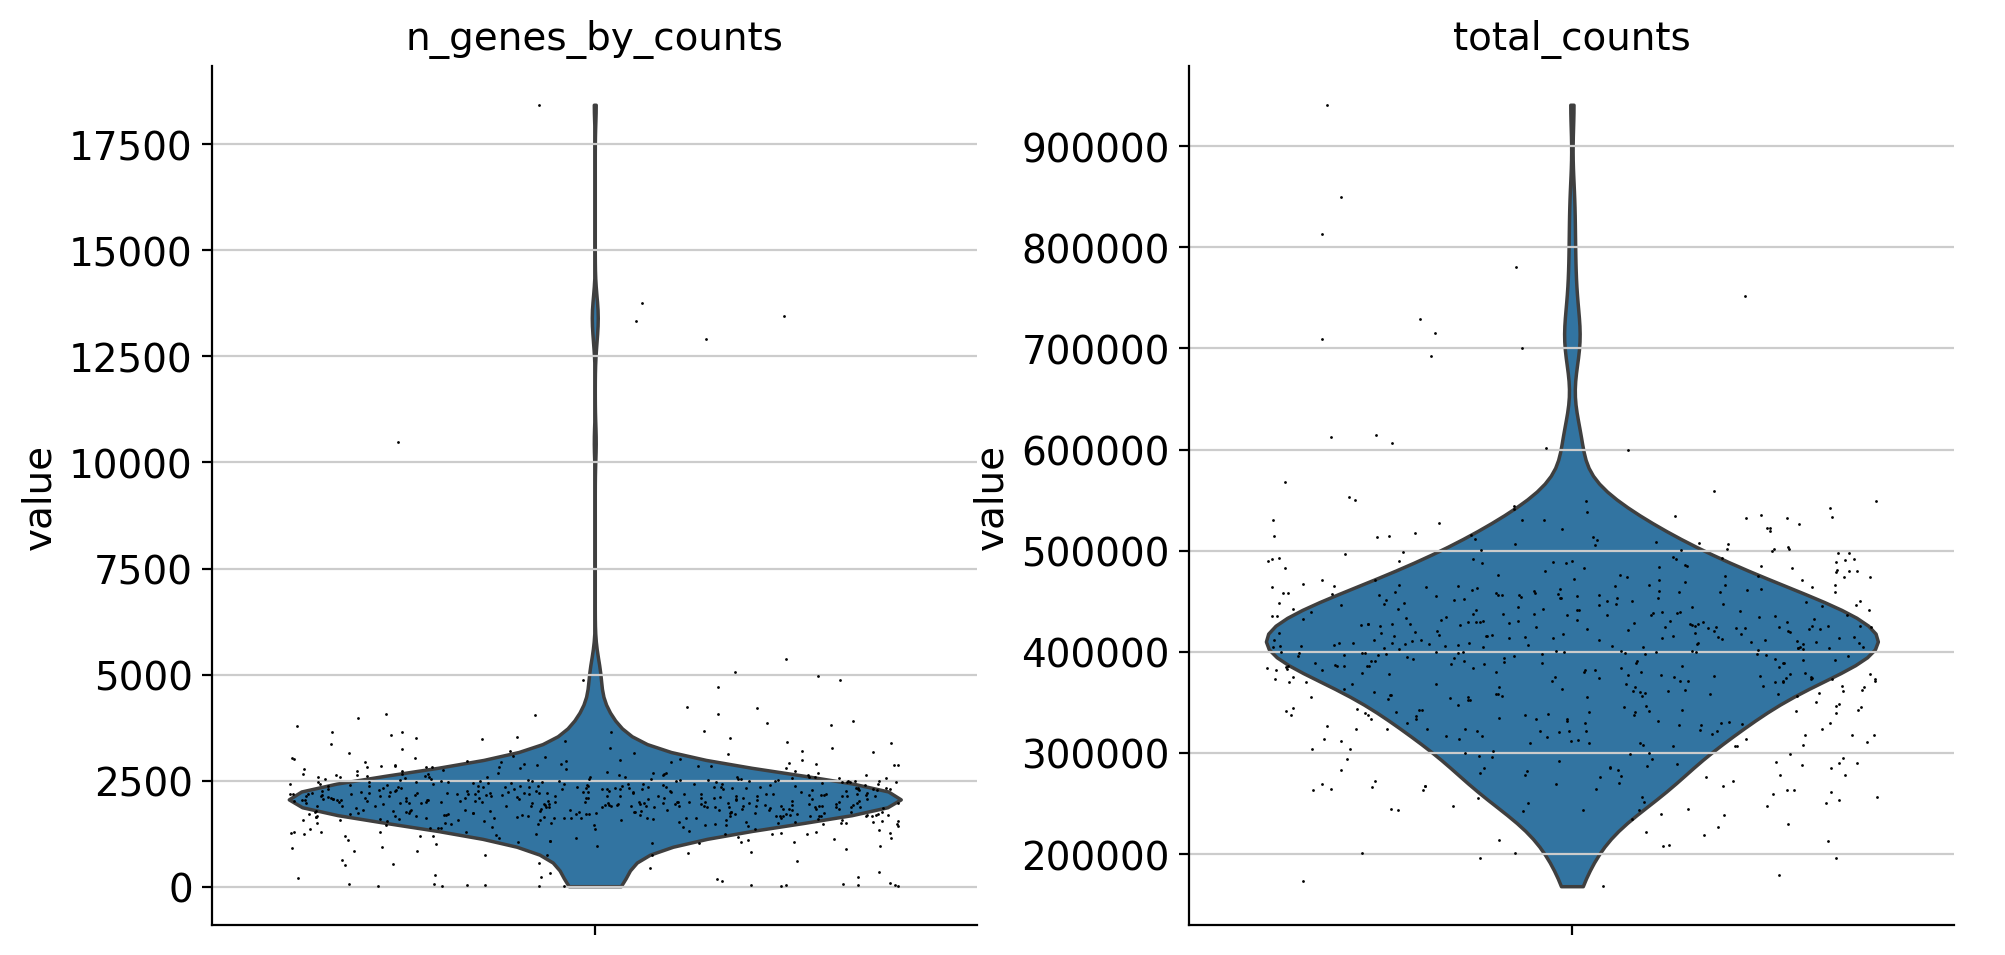

In [60]:
# n_genes_by_counts is number of genes with expression counts >=1
# total counts is the total number of counts for a cell or sum of counts for a gene (if we specify gene)
sc.pl.violin(
    adata_103334_0w,
    ["n_genes_by_counts", "total_counts"],
    jitter=0.4,
    multi_panel=True,
)

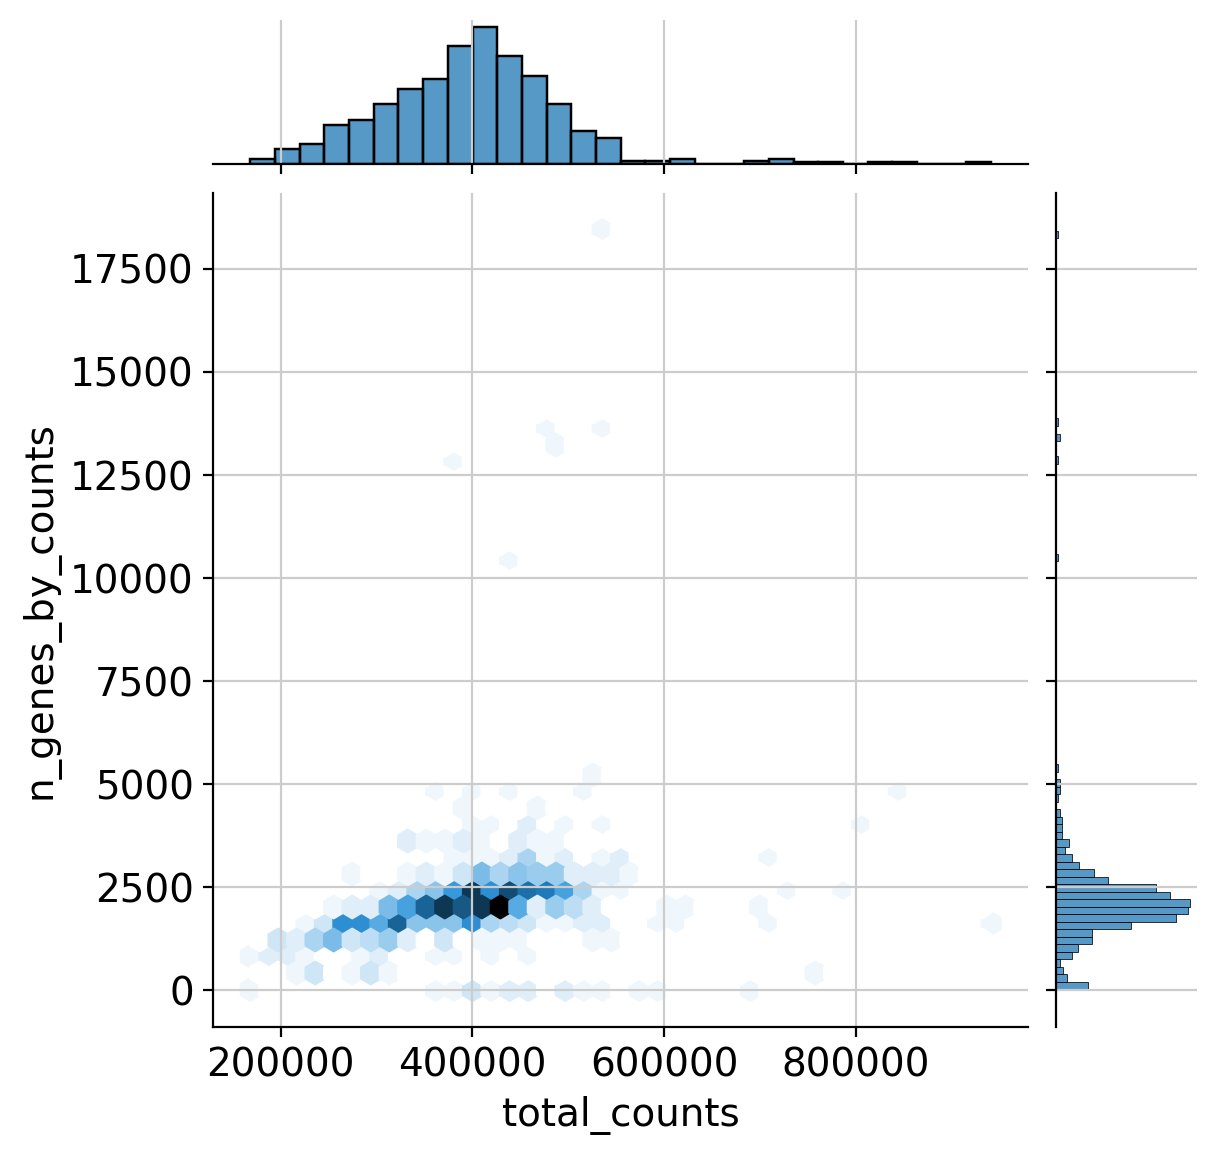

In [123]:
sns.jointplot(
    data=adata_103334_0w.obs,
    x="total_counts",
    y="n_genes_by_counts",
    kind="hex",
)

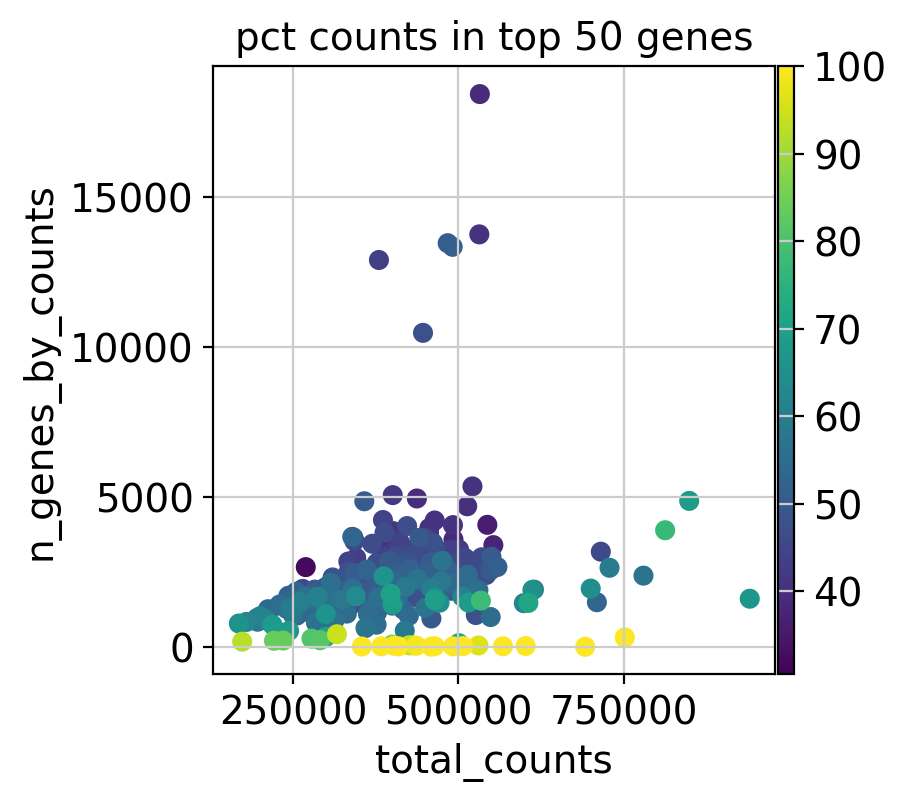

In [134]:
# pct_counts_in_top_50_genes is cumulative percentage of counts from the top 50 most expressed genes
sc.pl.scatter(adata_103334_0w, "total_counts", "n_genes_by_counts", color="pct_counts_in_top_50_genes")

### Identifying potential cell duplicates and normalizing data to median total counts and then log transform

In [ ]:
# Identifying doublets is crucial as they can lead to misclassifications or distortions in downstream analysis steps.
sc.pp.scrublet(adata, batch_key="sample")
# Saving count data
adata.layers["counts"] = adata.X.copy()
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)

### Identify highly variable genes in observations pre-PCA check

In [ ]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")
sc.pl.highly_variable_genes(adata_103334_0w)

### PCA + variance ratio plot + plot by PCAs and color by cell counts of top expressed genes

In [142]:
sc.tl.pca(adata_103334_0w)

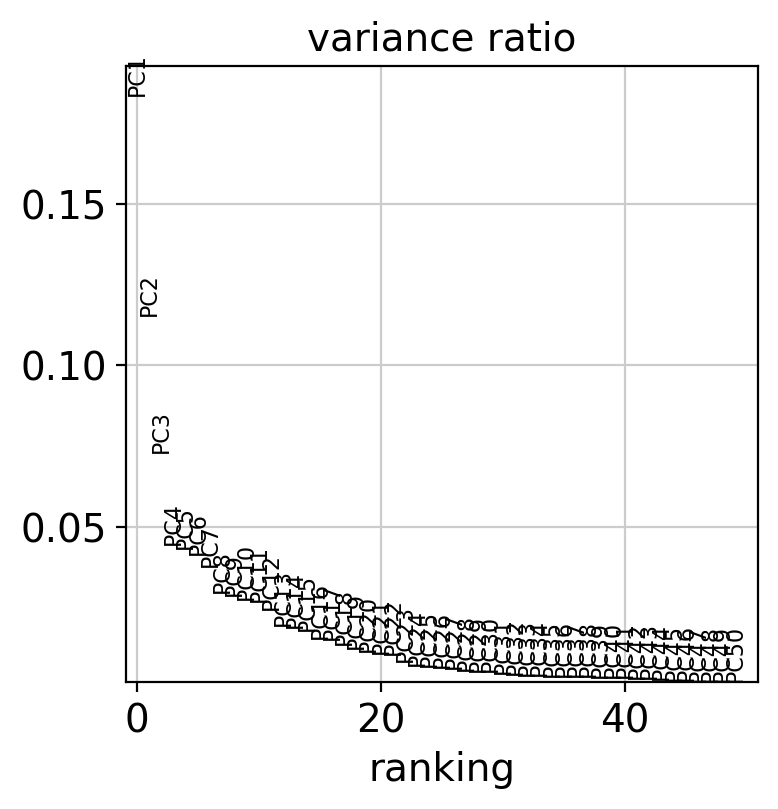

In [174]:
sc.pl.pca_variance_ratio(adata_103334_0w, n_pcs=50)

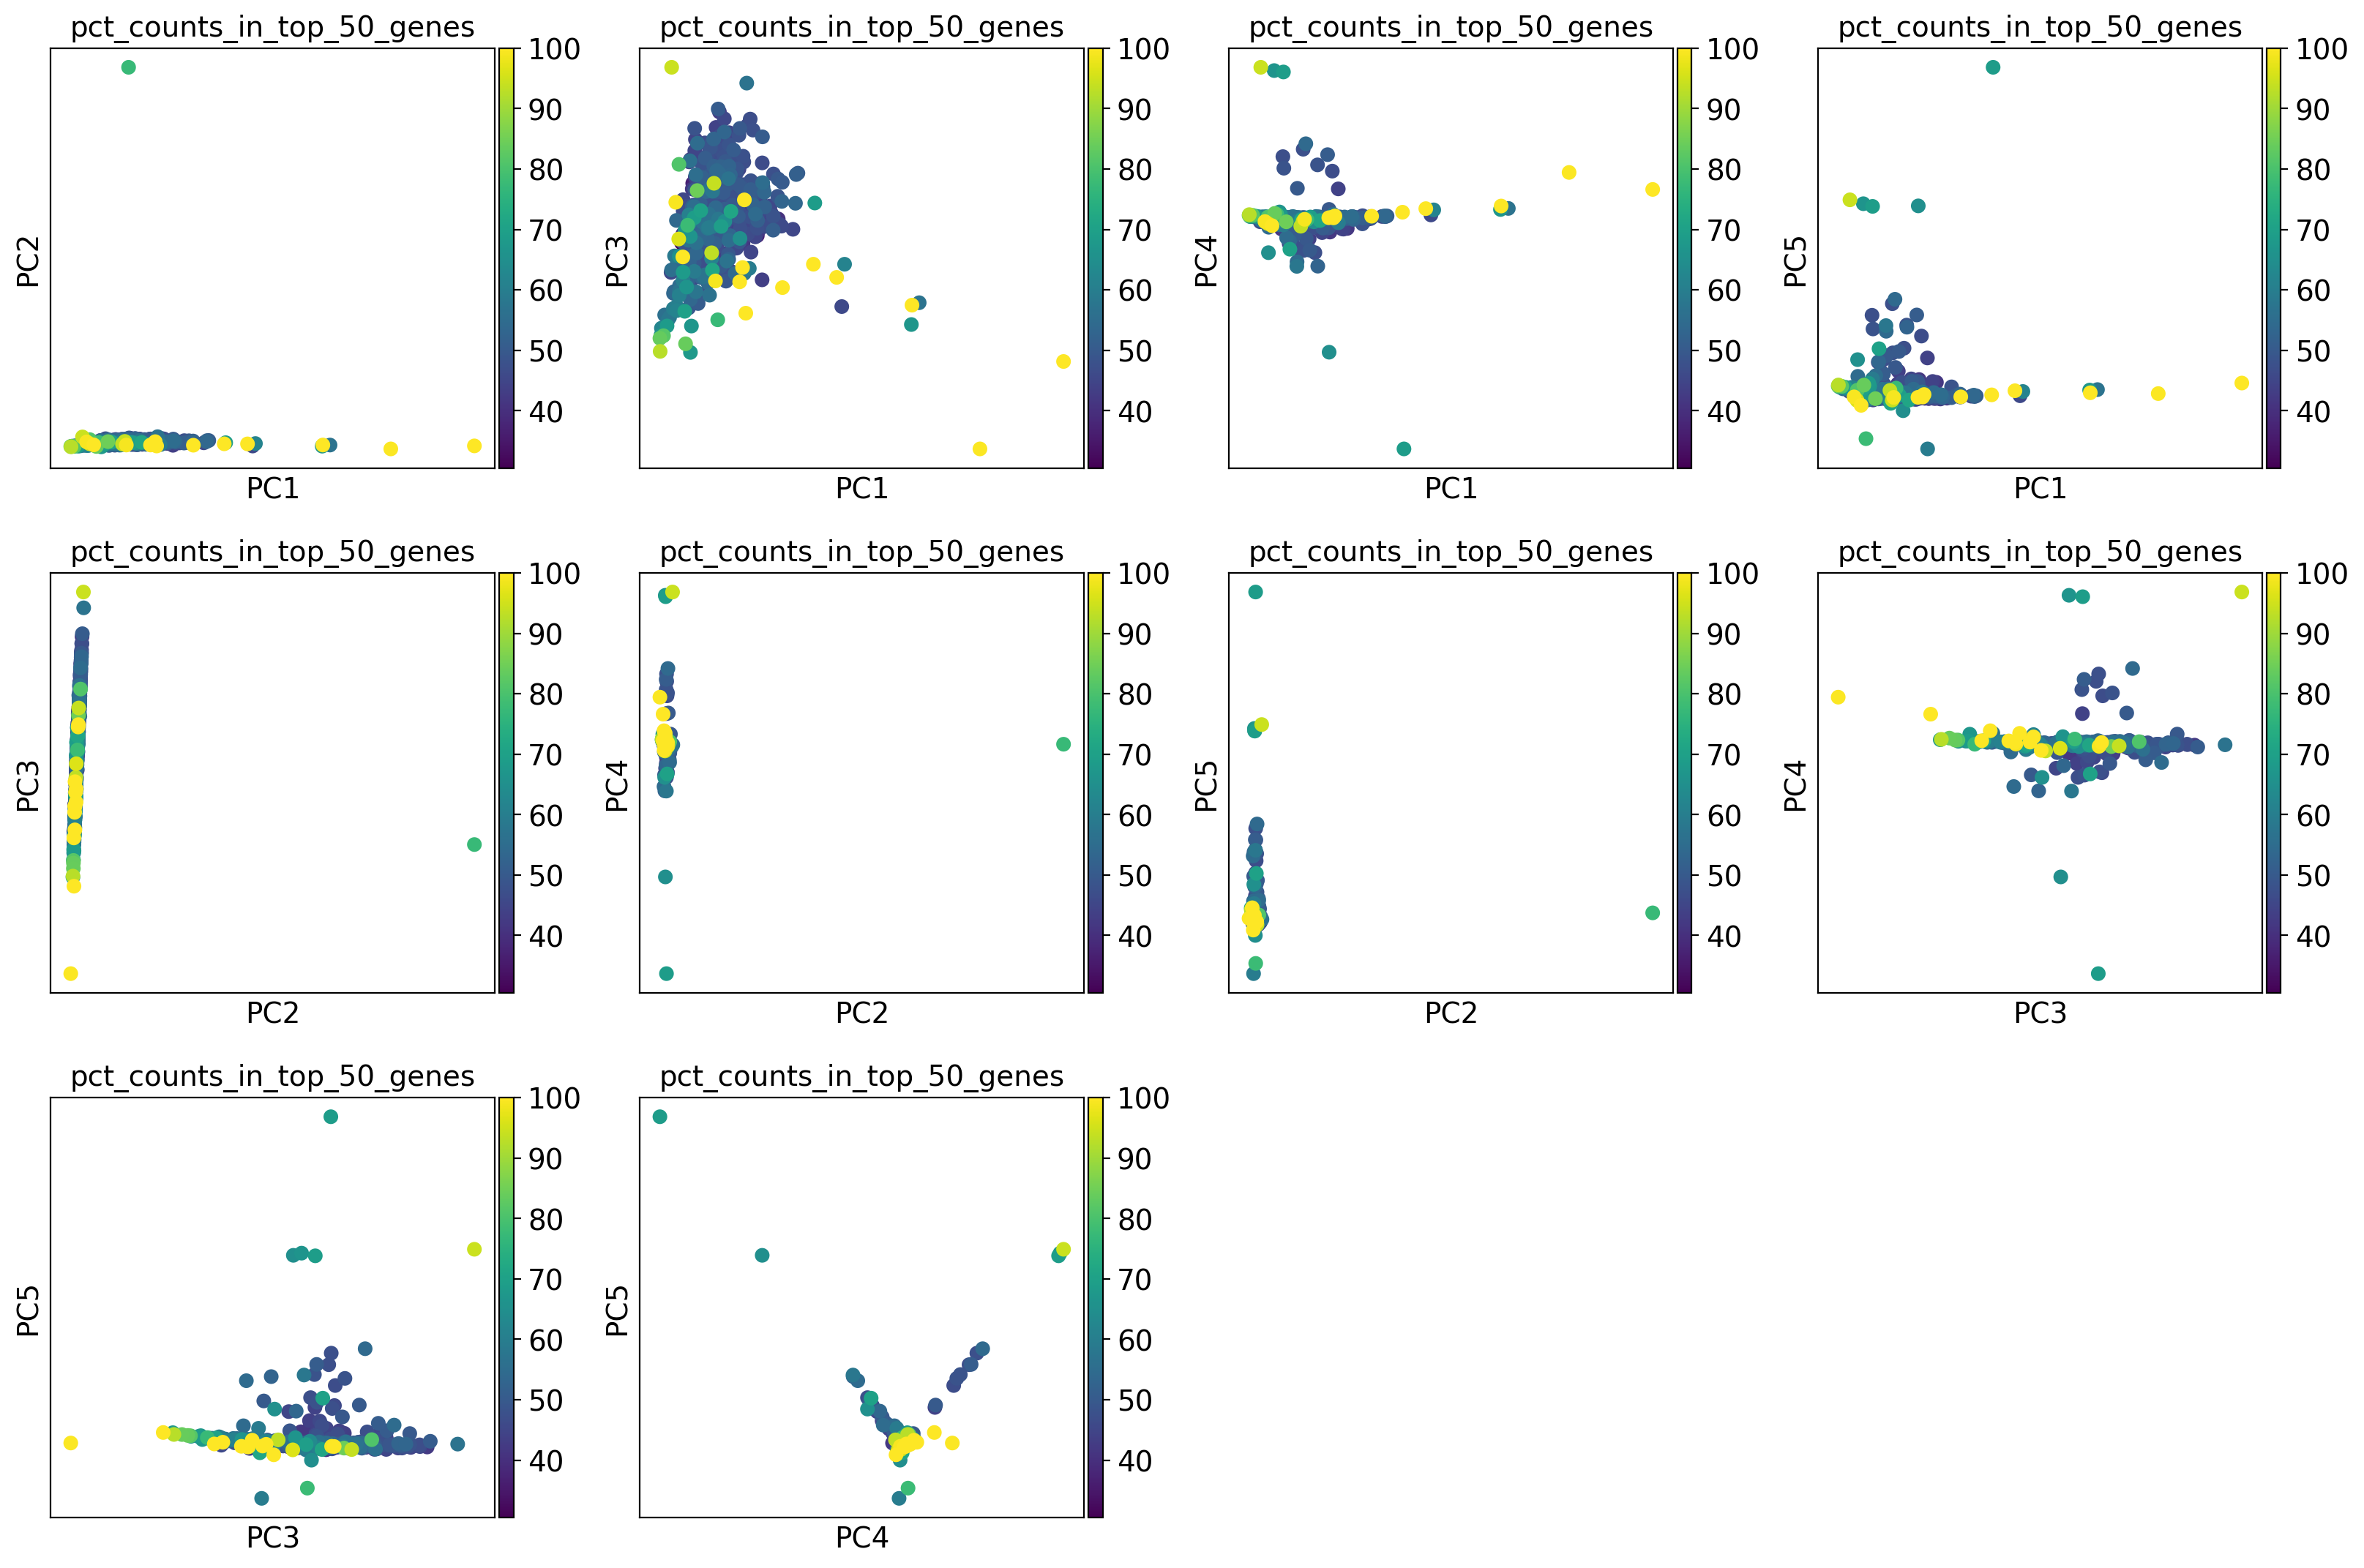

In [179]:
sc.pl.pca(
    adata_103334_0w,
    color="pct_counts_in_top_50_genes",
    dimensions=[(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)],
)

### Obtain neighbors in graph which Leiden clustering uses to cluster

In [146]:
sc.pp.neighbors(adata_103334_0w)

### Use UMAP dimensionality reduction and color by total gene expression count for that cell

In [147]:
sc.tl.umap(adata_103334_0w)

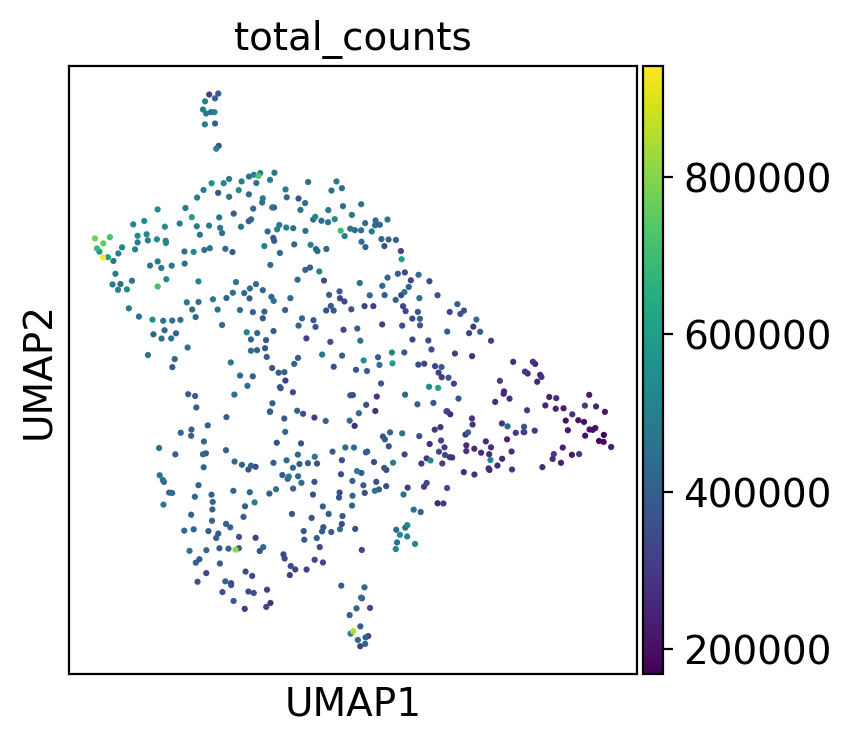

In [162]:
sc.pl.umap(
    adata_103334_0w,
    color="total_counts",
    size=20,
)

### Leiden clustering and UMAP on cells which directly clusters neighborhood graph of cells which we obtained using PCA

In [165]:
# Note that Leiden clustering directly clusters the neighborhood graph of cells, which we already computed in the previous section using the PCA results.
sc.tl.leiden(adata_103334_0w, flavor="igraph", n_iterations=2)

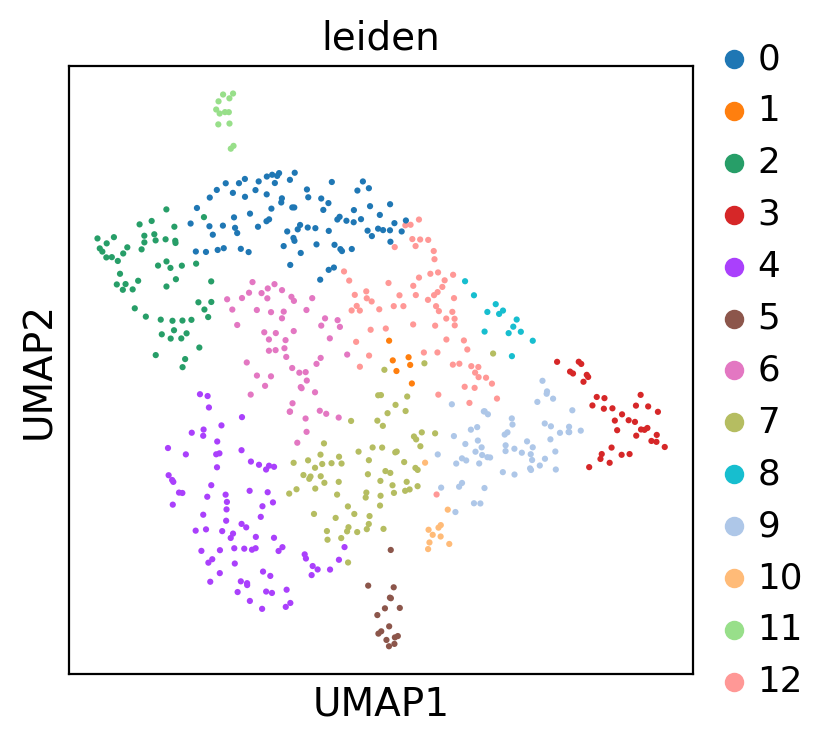

In [170]:
sc.pl.umap(adata_103334_0w, color=["leiden"], size=20)

### UMAP cluster by predicted doublect and doublet score, other QC metrics to perform quality control

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    # increase horizontal space between panels
    wspace=0.5,
    size=3,
)
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

### Vary resolution parameter in Leiden clustering to identify strong cell type clusters versus sub clusters versus over clustering

In [172]:
# Commonly and classically, cell type annotation uses those marker genes subsequent to the grouping of the cells into clusters. So, let’s generate a set of clustering solutions which we can then use to annotate our cell types. Here, we will use the Leiden clustering algorithm which will extract cell communities from our nearest neighbours graph.
# Notably, the number of clusters that we define is largely arbitrary, and so is the resolution parameter that we use to control for it. As such, the number of clusters is ultimately bound to the stable and biologically-meaningful groups that we can ultimately distringuish, typically done by experts in the corresponding field or by using expert-curated prior knowledge in the form of markers.
for res in [0.02, 0.5, 2.0]:
    sc.tl.leiden(adata_103334_0w, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph")

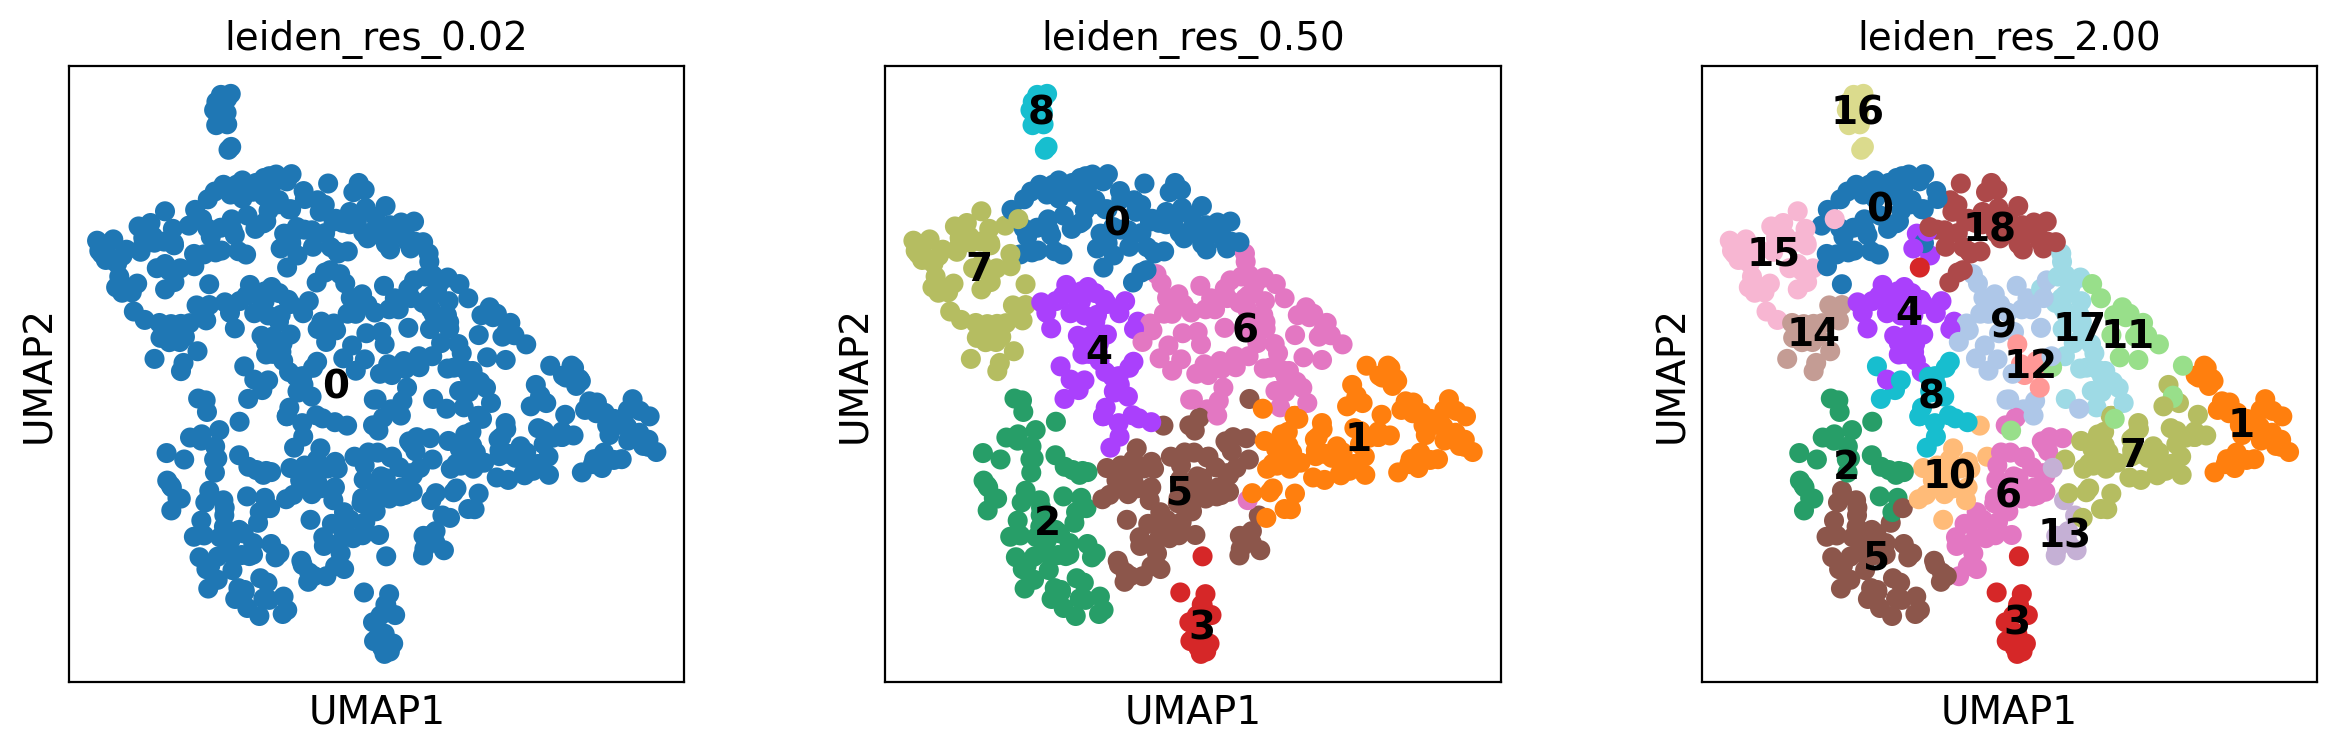

In [173]:
sc.pl.umap(
    adata_103334_0w,
    color=["leiden_res_0.02", "leiden_res_0.50", "leiden_res_2.00"],
    legend_loc="on data",
)

### Dotplot of marker genes to identify cell types and subtypes using different Leiden resolution params, understand which strongly expressed genes in which clusters have the highest cell count, fraction of cells in group, mean expression

In [ ]:
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    # Note: DMXL2 should be negative
    "cDC2": ["CST3", "COTL1", "LYZ", "DMXL2", "CLEC10A", "FCER1A"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    # Note HBM and GYPA are negative markers
    "Proerythroblast": ["CDK6", "SYNGR1", "HBM", "GYPA"],
    "NK": ["GNLY", "NKG7", "CD247", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    # Note IGHD and IGHM are negative markers
    "B cells": [
        "MS4A1",
        "ITGB1",
        "COL4A4",
        "PRDM1",
        "IRF4",
        "PAX5",
        "BCL11A",
        "BLK",
        "IGHD",
        "IGHM",
    ],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    # Note PAX5 is a negative marker
    "Plasmablast": ["XBP1", "PRDM1", "PAX5"],
    "CD4+ T": ["CD4", "IL7R", "TRBC2"],
    "CD8+ T": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"],
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
}
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.02", standard_scale="var")
adata.obs["cell_type_lvl1"] = adata.obs["leiden_res_0.02"].map(
    {
        "0": "Lymphocytes",
        "1": "Monocytes",
        "2": "Erythroid",
        "3": "B Cells",
    }
)
sc.pl.dotplot(adata, marker_genes, groupby="leiden_res_0.50", standard_scale="var")
# Obtain cluster-specific differentially expressed genes
sc.tl.rank_genes_groups(adata, groupby="leiden_res_0.50", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden_res_0.50", standard_scale="var", n_genes=5)

### Differentially expressed genes can be extracted in a convenient format with

In [ ]:
sc.get.rank_genes_groups_df(adata, group="7").head(5)

### UMAP clustering of ranked gene group expressions and leiden clustering with resolution 0.5

In [ ]:
dc_cluster_genes = sc.get.rank_genes_groups_df(adata, group="7").head(5)["names"]
sc.pl.umap(
    adata,
    color=[*dc_cluster_genes, "leiden_res_0.50"],
    legend_loc="on data",
    frameon=False,
    ncols=3,
)